# TP3 RedBaires. Simulador de eventos discretos

**Investigación Operativa 2, Grupo 02.** Parte B: implementación, verificación, validación y corridas en condiciones iniciales.

El cuaderno documenta el simulador construido a partir del modelo conceptual de la parte A. Todos los valores que aparecen en tablas, gráficos y conclusiones se calculan en las celdas de código a partir de los datos entregados (`TP3_datos.zip`) y de corridas reales del simulador; el texto no contiene resultados escritos a mano.

**Contenido**

1. Organización del código
2. Insumos estimados desde los datos
3. Eventos, lógicas y variables
4. Validación de la propagación contra la muestra
5. Escala de siembra y carga de la fila
6. Verificación y depuración
7. Variables de estado en el tiempo
8. Cálculo de la cantidad de réplicas
9. Corridas en condiciones iniciales con intervalos de confianza
10. Prueba de estrés
11. Diferencias con la parte A

## 1. Organización del código

El simulador se reparte en tres módulos:

| Módulo | Contenido |
|---|---|
| `insumos_redbaires.py` | Lectura y limpieza de los datos; estimación de cada parámetro de entrada (`estimar_insumos`). Devuelve un objeto `Insumos`. |
| `simulador_redbaires.py` | Clases `Configuracion` (variables de decisión), `Escenario`, `Supuestos` (cantidades sin datos y parámetros de la réplica), `SimuladorRedBaires` (eventos E1 a E4 y lógicas L1 a L4), `Informe` (variables de referencia, variables de estado promedio, indicadores y costos) y funciones `replicar`, `intervalo`, `informe_replicas` y `calibrar_escala`. |
| `validacion_redbaires.py` | Prueba de bondad de ajuste por Monte Carlo entre las cascadas simuladas y las observadas. |

Una corrida se pide con una configuración de las seis variables de decisión; el resultado es un informe:

```python
sim = SimuladorRedBaires(insumos)
informe, _ = sim.correr(Configuracion(M=2, C=1, U=5, F=0.25, D='mega', delta=0.5), escenario='conservador', semilla=1)
tabla = replicar(sim, Configuracion(M=2), n=20, semilla_base=1, procesos=2)   # una fila por réplica
informe_replicas(tabla)                                                         # medias e intervalos de confianza
```

Dos configuraciones corridas con la misma `semilla_base` comparten números aleatorios: cada pieza tiene su propio generador, sembrado con la semilla de la réplica y el número de pieza, y las llegadas tienen otro generador independiente de la configuración. La sincronización es completa hasta que una variable de decisión cambia la historia de una pieza (un reenvío bloqueado o una remoción); desde ahí, esa pieza consume sus números en otro orden.

In [1]:
import math, pickle, time, inspect, warnings
from dataclasses import asdict
import numpy as np, pandas as pd, scipy.stats as st
import matplotlib.pyplot as plt
from insumos_redbaires import estimar_insumos, Insumos, NIVELES
from simulador_redbaires import (SimuladorRedBaires, Configuracion, Supuestos, Escenario, ESCENARIOS,
                                 replicar, intervalo, informe_replicas, calibrar_escala)
from validacion_redbaires import prueba_bondad, INTERVALOS, ETIQUETAS
def n(x, d=4):
    # número con formato es-AR: punto de miles y coma decimal
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')
pd.set_option('display.float_format', lambda v: n(v, 4))
pd.set_option('display.width', 160)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
PROCESOS = 2
t_inicio_cuaderno = time.time()

# Las corridas largas se guardan en disco al terminar, solo para poder retomar la ejecución si se interrumpe.
# La carpeta lleva un resumen (hash) del código de los tres módulos: si el código cambia, todo se recalcula.
import os, hashlib
_codigo = b''.join(open(m, 'rb').read() for m in ['insumos_redbaires.py', 'simulador_redbaires.py', 'validacion_redbaires.py'])
CACHE = os.path.join('resultados_corridas', hashlib.sha256(_codigo).hexdigest()[:12])
os.makedirs(CACHE, exist_ok=True)
print('Carpeta de resultados de esta versión del código:', CACHE)
def en_disco(nombre, funcion):
    ruta = os.path.join(CACHE, nombre + '.pkl')
    if os.path.exists(ruta):
        with open(ruta, 'rb') as f:
            return pickle.load(f)
    r = funcion()
    with open(ruta, 'wb') as f:
        pickle.dump(r, f)
    return r

Carpeta de resultados de esta versión del código: resultados_corridas/5839dc12eb10


## 2. Insumos estimados desde los datos

`estimar_insumos` aplica la limpieza del modelo de datos de la parte A (duplicados, códigos en mayúsculas, fechas centinela 2099, retardos negativos, seguidores nulos) y estima cada parámetro. La tabla compara lo estimado con el valor informado en la parte A, redondeado a los decimales con que allí se informó.

In [2]:
I = estimar_insumos('TP3_datos.zip')
c = I.coef
piezas_dia = I.semillas_por_dia * I.escala
rate_leg = I.recall_ev * I.pi_ev * (1 - I.precision_ev) / (I.precision_ev * (1 - I.pi_ev))
filas = [
    # (insumo, estimado, valor informado en la parte A, decimales)
    ('Proporción de piezas nocivas', I.p_nociva, 0.417, 3),
    ('Proporción de piezas con señal C2', I.p_c2, 0.103, 3),
    ('Vida media: sigma lognormal', I.vm_sigma, 0.889, 3),
    ('Vida media: mediana (min)', I.vm_mediana, 220.8, 1),
    ('Hijos: r de la binomial negativa', I.r_nb, 1.25, 2),
    ('Hijos: constante (media nano por Mensajes)', math.exp(c['intercepto']), 0.448, 3),
    ('Hijos: factor nivel mega', math.exp(c['nivel'][3]), 7.172, 3),
    ('Hijos: factor por generación', math.exp(c['gen']), 0.900, 3),
    ('Hijos: coeficiente de la edad relativa', c['edad_rel'], -0.678, 3),
    ('Media de hijos por reenvío m', I.m_reenvio, 0.784, 3),
    ('Retardo: peso de la fase rápida (hiperexponencial)', I.w_rapida, 0.534, 3),
    ('Retardo: media de la fase rápida (min)', I.media_rapida, 14.3, 1),
    ('Retardo: media de la fase diferida (min)', I.media_diferida, 134.8, 1),
    ('Fracción de seguidores: c Weibull', I.frac_c, 1.336, 3),
    ('Fracción de seguidores: escala Weibull', I.frac_escala, 0.200, 3),
    ('Centinela C = 0: P(marca | nociva)', I.recall_ev, 0.336, 3),
    ('Centinela C = 0: P(marca | legítima)', rate_leg, 0.167, 3),
    ('Escala de siembra ESC', I.escala, 320, 0),
    ('Piezas sembradas por día con ESC', piezas_dia, 8894, 0),
    ('Cuentas mega distintas NDEG', I.ndeg, 231, 0),
]
tab_ins = pd.DataFrame(filas, columns=['insumo', 'estimado', 'parte A', 'decimales'])
tab_ins['coincide'] = [round(e, d) == round(a, d) for _, e, a, d in filas]
print(tab_ins.drop(columns='decimales').to_string(index=False))
assert tab_ins.coincide.all(), 'algún insumo no reproduce el valor informado en la parte A'

                                            insumo   estimado    parte A  coincide
                      Proporción de piezas nocivas     0,4170     0,4170      True
                 Proporción de piezas con señal C2     0,1028     0,1030      True
                       Vida media: sigma lognormal     0,8891     0,8890      True
                         Vida media: mediana (min)   220,8391   220,8000      True
                  Hijos: r de la binomial negativa     1,2500     1,2500      True
        Hijos: constante (media nano por Mensajes)     0,4485     0,4480      True
                          Hijos: factor nivel mega     7,1722     7,1720      True
                      Hijos: factor por generación     0,8996     0,9000      True
            Hijos: coeficiente de la edad relativa    -0,6779    -0,6780      True
                      Media de hijos por reenvío m     0,7835     0,7840      True
Retardo: peso de la fase rápida (hiperexponencial)     0,5339     0,5340      True
    

In [3]:
print('Fases del retardo en la mezcla de exponenciales (peso, media en min, espera en min):')
print(pd.DataFrame(I.fases_retardo, columns=['peso', 'media_min', 'espera_min']).to_string())
print(f"\nRetardos observados: {n(len(I.observado['retardos']), 0)}; corte de la fase diferida: {n(I.corte_retardo, 0)} min")
print(f"Cascadas observadas: {n(len(I.observado['tamano']), 0)}; tope de tamaño: {I.observado['tope']}")

Fases del retardo en la mezcla de exponenciales (peso, media en min, espera en min):
    peso  media_min  espera_min
0 0,1040     1,0080      0,0000
1 0,4764    23,1974      0,0000
2 0,3640    50,1889     55,0000
3 0,0555   322,9610     55,0000

Retardos observados: 53.826; corte de la fase diferida: 55 min
Cascadas observadas: 5.000; tope de tamaño: 500


## 3. Eventos, lógicas y variables

| Elemento | Implementación |
|---|---|
| E1 Aparición de una pieza | Llegadas de un proceso de Poisson no estacionario con tasa λ(día, hora) × ESC, generado por aceptación y rechazo (`proxima_llegada` dentro de `correr`). La pieza recibe sus atributos (`_crear_pieza`) y la semilla se procesa con `_semilla`. |
| E2 Reenvío | `_reenvio`: elige la generación del padre, aplica L2, sortea nivel, superficie y verificación de la cuenta, aplica L3, sortea impresiones y marcado (L1) y suma potencial. `_proximo` programa el siguiente reenvío de la pieza o detecta el fin natural. |
| E3 Ingreso a la fila | Ocurre DER minutos después del primer marcado. Si hay moderador libre empieza la revisión; si no, el caso espera (fila FIFO). |
| E4 Fin de revisión | L4: la pieza se remueve con probabilidad PREM (reducida a la mitad si la cuenta semilla está verificada). La remoción invalida el reenvío pendiente (control por versión). |
| Fin natural y fin de la réplica | Condiciones, no eventos: la pieza termina cuando `_proximo` no encuentra un próximo reenvío; la réplica termina al vaciar la lista de eventos hasta el fin del horizonte. |
| L1 Centinela | P(marca) = recall si la aparición es nociva y recall·π·(1 − precisión) / (precisión·(1 − π)) si es legítima. |
| L2 Fricción | Si la pieza acumula R_i ≥ U reenvíos, cada reenvío posterior se bloquea con probabilidad F; el bloqueado no genera impresiones ni potencial. |
| L3 Degradación | Si la cuenta es mega y D incluye mega, o la pieza es C2 y D incluye C2, impresiones y potencial se multiplican por (1 − δ). |
| L4 Revisión | Ver E4. Si la cascada ya terminó, la remoción no cambia PA. |

**Mecanismo de propagación.** Cada aparición suma a la pieza un potencial J ~ Gamma(r, μ/r), con μ dada por la regresión binomial negativa. El potencial se reparte entre las fases del retardo; en cada fase decae como exp(−κ s) y el próximo reenvío se sortea por inversión. La cantidad total de hijos de una aparición resulta Poisson con media J, es decir, binomial negativa con media μ, y cada hijo llega con el retardo de la mezcla de fases. La pieza guarda su potencial por generación y por fase, de modo que la memoria no crece con el tamaño de la cascada.

**Variables de estado.** QM, BM y UM cambian solo en E3 y E4; PA cambia en E1, al terminar una pieza y en E4; R_i cambia en E2. Los promedios temporales se acumulan en esos mismos eventos (integral por tramos de la función escalón). La ventana de medición excluye el primer día (calentamiento) y dura 30 días.

El código de las dos funciones centrales de la propagación:

In [4]:
print(inspect.getsource(SimuladorRedBaires._reenvio))
print(inspect.getsource(SimuladorRedBaires._proximo))

    def _reenvio(self, p, t):
        """Lógica de E2 sobre la pieza. Devuelve None si la fricción bloquea el reenvío, o (impresiones, marcada)."""
        rng, c, cfg = p.rng, self.I.coef, self.cfg
        if self.con_espera:
            self._activar_vencidas(p, t)
        gp = self._elegir_generacion(p, p.prox_fase)
        u = rng.random()                         # se sortea siempre, para conservar los números aleatorios comunes
        if cfg.F > 0 and p.R >= cfg.U and u < cfg.F:                              # L2
            return None
        d = gp + 1
        p.R += 1
        p.eventos += 1
        p.prof = max(p.prof, d)
        p.t_ult = t
        nivel = self._elegir(rng, self.cum_hijo)
        sup = self._elegir(rng, self.cum_sup)
        ver = int(rng.random() < self.p_ver[nivel])
        degr = (self.deg_mega and nivel == MEGA) or p.deg_c2                      # L3
        imp = self._impresiones(rng, nivel, degr)
        marcada = rng.random() < self.p_marca[p.nociva]  

## 4. Validación de la propagación contra la muestra

La muestra no registra remociones, así que la validación compara la propagación sin moderación con las 5.000 cascadas observadas, con el mismo tope de 500 eventos. `simular_cascadas` usa exactamente las funciones de E1 y E2 del simulador completo.

**Prueba.** Bondad de ajuste por Monte Carlo (bootstrap paramétrico). Una simulación de referencia de 200.000 cascadas estima la distribución del modelo. Para la muestra observada se calcula un estadístico de discrepancia contra la referencia: chi cuadrado por intervalos para tamaño y profundidad, distancia de Kolmogorov-Smirnov para la duración y diferencia absoluta para la proporción de piezas marcadas. Luego se simulan R muestras independientes del mismo tamaño que la observada y se calcula el mismo estadístico para cada una; el valor p es la proporción de muestras simuladas con discrepancia mayor o igual que la observada. Como los parámetros se estimaron con la misma muestra, la prueba es conservadora (tiende a no rechazar).

Se prueban tres representaciones del retardo padre-hijo:

* `h2`: hiperexponencial de dos fases, como en la parte A.
* `h2_espera`: la fase diferida empieza después del corte de 55 min, que la parte A deja como alternativa.
* `mezcla`: mezcla de exponenciales ajustada por máxima verosimilitud a los retardos observados; dos fases empiezan de inmediato y dos después del corte de 55 min.

In [5]:
sim = SimuladorRedBaires(I)
R_BOOT = 300
validacion = {}
for ret in ['h2', 'h2_espera', 'mezcla']:
    t0 = time.time()
    tabla, comparacion, ref = en_disco(f'validacion_{ret}', lambda: prueba_bondad(sim, I.observado, retardo=ret, n_ref=200_000, R=R_BOOT, semilla=1, procesos=PROCESOS))
    validacion[ret] = dict(tabla=tabla, comparacion=comparacion, ref=ref)
    print(f'Retardo {ret} ({n(time.time() - t0, 0)} s, R = {R_BOOT} muestras simuladas)')
    print(tabla.to_string(), '\n')

Retardo h2 (130 s, R = 300 muestras simuladas)
                                                     estadístico observado  percentil 95 simulado  valor p
variable                                                                                                  
Tamaño (chi cuadrado, 10 intervalos)                                9,3165                17,5303   0,4319
Profundidad (chi cuadrado, 9 intervalos)                           17,6774                15,2962   0,0432
Duración (Kolmogorov-Smirnov)                                       0,0382                 0,0189   0,0033
Proporción de piezas marcadas (diferencia absoluta)                 0,0433                 0,0153   0,0033 



Retardo h2_espera (140 s, R = 300 muestras simuladas)
                                                     estadístico observado  percentil 95 simulado  valor p
variable                                                                                                  
Tamaño (chi cuadrado, 10 intervalos)                               13,0494                17,4597   0,1628
Profundidad (chi cuadrado, 9 intervalos)                           26,0007                15,6988   0,0033
Duración (Kolmogorov-Smirnov)                                       0,0378                 0,0187   0,0033
Proporción de piezas marcadas (diferencia absoluta)                 0,0411                 0,0141   0,0033 



Retardo mezcla (206 s, R = 300 muestras simuladas)
                                                     estadístico observado  percentil 95 simulado  valor p
variable                                                                                                  
Tamaño (chi cuadrado, 10 intervalos)                               10,9177                16,7735   0,2658
Profundidad (chi cuadrado, 9 intervalos)                           17,8795                14,0510   0,0233
Duración (Kolmogorov-Smirnov)                                       0,0168                 0,0185   0,1096
Proporción de piezas marcadas (diferencia absoluta)                 0,0426                 0,0132   0,0033 



In [6]:
resumen_val = pd.DataFrame({ret: v['tabla']['valor p'] for ret, v in validacion.items()})
print('Valores p por representación del retardo:')
print(resumen_val.to_string())

Valores p por representación del retardo:
                                                        h2  h2_espera  mezcla
variable                                                                     
Tamaño (chi cuadrado, 10 intervalos)                0,4319     0,1628  0,2658
Profundidad (chi cuadrado, 9 intervalos)            0,0432     0,0033  0,0233
Duración (Kolmogorov-Smirnov)                       0,0033     0,0033  0,1096
Proporción de piezas marcadas (diferencia absoluta) 0,0033     0,0033  0,0033


Las tres pruebas de propagación (tamaño, profundidad y duración) se hacen sobre la misma muestra. Para controlar la probabilidad de rechazar alguna por azar se aplica, además del nivel individual del 5 %, la corrección de Holm para las tres pruebas simultáneas. La proporción de piezas marcadas se analiza aparte porque corresponde a un supuesto declarado en la parte A (S11: el puntaje de nocividad no se modela y Centinela marca cada aparición en forma independiente).

In [7]:
def holm(p, alfa=0.05):
    orden = np.argsort(p); m = len(p); rechaza = np.zeros(m, bool)
    for k, i in enumerate(orden):
        if p[i] <= alfa / (m - k):
            rechaza[i] = True
        else:
            break
    return rechaza

prop = ['Tamaño (chi cuadrado, 10 intervalos)', 'Profundidad (chi cuadrado, 9 intervalos)', 'Duración (Kolmogorov-Smirnov)']
for ret in validacion:
    p = resumen_val.loc[prop, ret].values
    ind = p <= 0.05; h = holm(p)
    print(f'{ret:10s}: rechazos al 5 % individual: {[n.split(" (")[0] for n, r in zip(prop, ind) if r] or "ninguno"}; '
          f'con Holm: {[n.split(" (")[0] for n, r in zip(prop, h) if r] or "ninguno"}')

h2        : rechazos al 5 % individual: ['Profundidad', 'Duración']; con Holm: ['Duración']
h2_espera : rechazos al 5 % individual: ['Profundidad', 'Duración']; con Holm: ['Profundidad', 'Duración']
mezcla    : rechazos al 5 % individual: ['Profundidad']; con Holm: ninguno


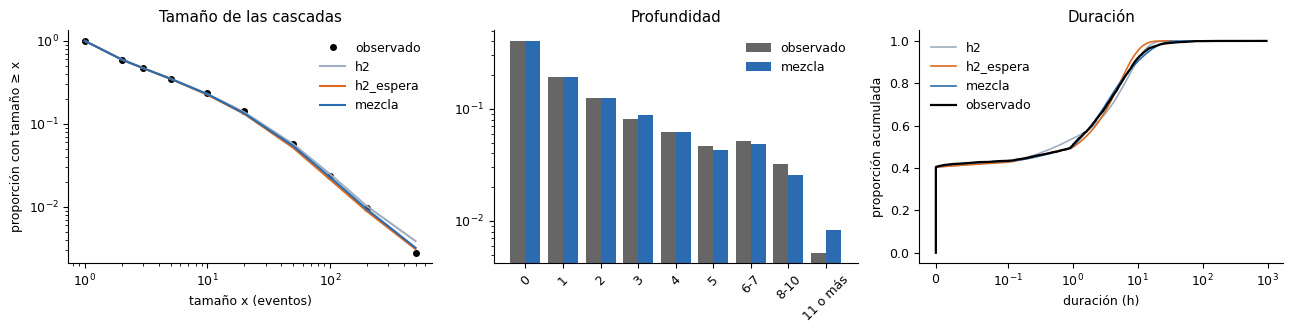

In [8]:
o = I.observado
ok = ~np.isnan(o['duracion_h'])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
umb = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200, 500])
ax[0].loglog(umb, [(o['tamano'] >= u).mean() for u in umb], 'ko', ms=4, label='observado')
for ret, col in zip(validacion, ['#a0aec0', '#dd6b20', '#2b6cb0']):
    r = validacion[ret]['ref']
    ax[0].loglog(umb, [(r.tamano >= u).mean() for u in umb], '-', color=col, label=ret)
    xs = np.sort(r.duracion_h.values)
    ax[2].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=col, lw=1.2, label=ret)
ax[0].set_xlabel('tamaño x (eventos)'); ax[0].set_ylabel('proporción con tamaño ≥ x'); ax[0].set_title('Tamaño de las cascadas'); ax[0].legend(frameon=False)
cmp = validacion['mezcla']['comparacion']['profundidad']
xx = np.arange(len(cmp))
ax[1].bar(xx - 0.2, cmp.observado, 0.4, color='k', alpha=.6, label='observado')
ax[1].bar(xx + 0.2, cmp.simulado, 0.4, color='#2b6cb0', label='mezcla')
ax[1].set_xticks(xx, cmp.index, rotation=45); ax[1].set_yscale('log'); ax[1].set_title('Profundidad'); ax[1].legend(frameon=False)
xs = np.sort(o['duracion_h'][ok])
ax[2].plot(xs, np.arange(1, len(xs) + 1) / len(xs), 'k', lw=1.6, label='observado')
ax[2].set_xscale('symlog', linthresh=0.1); ax[2].set_xlabel('duración (h)'); ax[2].set_ylabel('proporción acumulada'); ax[2].set_title('Duración'); ax[2].legend(frameon=False)
plt.tight_layout(); plt.show()

In [9]:
for v in ['tamano', 'profundidad']:
    print(f'Distribución de {v} (proporciones), retardo mezcla:')
    print(validacion['mezcla']['comparacion'][v].T.to_string(), '\n')
r = validacion['mezcla']['ref']
cuant = pd.DataFrame({'observado': np.quantile(o['duracion_h'][ok], [.25, .5, .75, .9])} |
                     {ret: validacion[ret]['ref'].duracion_h.quantile([.25, .5, .75, .9]).values for ret in validacion},
                     index=['cuartil 1', 'mediana', 'cuartil 3', 'percentil 90'])
print('Cuantiles de la duración de las cascadas (h):')
print(cuant.to_string())
print(f"Proporción de piezas marcadas (cascadas con tope de 500): observada {n(o['marcada'].mean(), 4)}; simulada {n(r.marcada.mean(), 4)}")

Distribución de tamano (proporciones), retardo mezcla:
               1      2      3    4-5   6-10  11-20  21-50  51-100  101-499  500 (tope)
observado 0,4038 0,1272 0,0756 0,0796 0,0918 0,0852 0,0810  0,0326   0,0204      0,0028
simulado  0,4037 0,1278 0,0704 0,0838 0,1013 0,0846 0,0754  0,0304   0,0194      0,0032 

Distribución de profundidad (proporciones), retardo mezcla:
               0      1      2      3      4      5    6-7   8-10  11 o más
observado 0,4038 0,1928 0,1248 0,0812 0,0620 0,0464 0,0518 0,0320    0,0052
simulado  0,4037 0,1940 0,1252 0,0881 0,0626 0,0433 0,0490 0,0259    0,0083 

Cuantiles de la duración de las cascadas (h):
              observado     h2  h2_espera  mezcla
cuartil 1        0,0000 0,0000     0,0000  0,0000
mediana          0,9406 0,5388     1,0231  0,9694
cuartil 3        4,3079 5,0790     4,3832  4,0606
percentil 90     8,9162 9,5187     7,6312  9,7237
Proporción de piezas marcadas (cascadas con tope de 500): observada 0,4934; simulada 0,5360


**Lectura.** Con la hiperexponencial de la parte A la duración de las cascadas no se reproduce: la mediana simulada queda corta respecto de la observada y la prueba rechaza. Con la espera previa en la fase diferida la mediana se acerca a la observada, pero la cola superior no (el percentil 90 queda corto en la tabla de cuantiles) y la prueba también rechaza. La mezcla de exponenciales con espera no muestra diferencia significativa en tamaño ni en duración. La profundidad se rechaza al 5 % individual y no se rechaza con la corrección de Holm para las tres pruebas; el modelo produce algo más de cascadas de 11 o más generaciones que las observadas. El simulador adopta la mezcla como representación del retardo (es el valor por defecto de `Supuestos.retardo`); las otras dos quedan disponibles como opciones.

Dos advertencias sobre el alcance de la validación. La mezcla se eligió entre tres representaciones mirando estas mismas pruebas, de modo que sus valores p están algo sesgados a favor. Y la prueba no vuelve a estimar los parámetros en cada muestra simulada, lo que la hace conservadora: un no rechazo es evidencia de compatibilidad, no prueba de que el modelo sea correcto.

La proporción de piezas con al menos un marcado es mayor en el modelo que en la muestra, como anticipó el supuesto S11: el marcado por aparición sí coincide con el observado (sus probabilidades salen de la precisión y el recall por aparición), pero en los datos los marcados se concentran en menos piezas. La consecuencia operativa es que el modelo genera más casos por pieza que los observados; la sección siguiente la compensa en la escala de siembra.

In [10]:
# Marcado por aparición: proporción de apariciones marcadas en la muestra contra la probabilidad que usa L1 con C = 0
p_l1 = I.pi_ev * I.recall_ev + (1 - I.pi_ev) * rate_leg
print(f"Apariciones marcadas en la muestra: {n(I.observado['p_marca_aparicion'], 4)}; probabilidad de marcado de una aparición según L1: {n(p_l1, 4)}")
print('La coincidencia es algebraica: π · recall / precisión es la proporción de apariciones marcadas.')

Apariciones marcadas en la muestra: 0,2339; probabilidad de marcado de una aparición según L1: 0,2339
La coincidencia es algebraica: π · recall / precisión es la proporción de apariciones marcadas.


## 5. Escala de siembra y carga de la fila

La parte A calibró ESC para que los casos lleguen a la fila con la tasa λ que explica la latencia observada (M/M/1 con el tiempo de revisión TREV): ESC = λ / (piezas marcadas por día en la muestra). Como el modelo marca una proporción de piezas mayor que la observada, con ESC de la parte A la tasa de casos simulada supera a λ y, con un solo moderador, también a la tasa de servicio μ: la fila no tendría régimen estable. `calibrar_escala` mantiene el criterio de la parte A y reemplaza la proporción observada por la simulada.

In [11]:
ESC_B, p_marcada_sim = en_disco('escala', lambda: calibrar_escala(sim, n=100_000, semilla=7, retardo='mezcla'))
lam, mu = I.observado['lambda_casos_min'], I.observado['mu_casos_min']
lam_A = I.escala * I.semillas_por_dia * p_marcada_sim / 1440
print(f'λ calibrada en la parte A: {n(lam, 4)} casos/min; μ = {n(mu, 4)} casos/min')
print(f'Proporción de piezas marcadas (cascadas sin tope; semillas con fecha): muestra {n(I.observado["marcadas_por_dia"] / I.semillas_por_dia, 4)}; modelo {n(p_marcada_sim, 4)}')
print(f'Con ESC de la parte A ({n(I.escala, 2)}) la tasa esperada de casos es {n(lam_A, 4)}/min: ρ = {n(lam_A / mu, 4)} con M = 1')
print(f'ESC recalibrada: {n(ESC_B, 2)} ({n(ESC_B * I.semillas_por_dia, 0)} piezas por día); ρ medio = {n(lam / mu, 4)} con M = 1 (por construcción)')
tasa_h = I.tasa_dia_hora * ESC_B * p_marcada_sim / 60
print(f'Con la siembra por día y hora, ρ horario con M = 1 va de {n(tasa_h.min() / mu, 3)} a {n(tasa_h.max() / mu, 3)}; '
      f'{n(100 * (tasa_h > mu).mean(), 1)} % de las horas de la semana tienen ρ > 1')
SUP = Supuestos(retardo='mezcla', escala=ESC_B)

λ calibrada en la parte A: 3,0488 casos/min; μ = 3,0556 casos/min
Proporción de piezas marcadas (cascadas sin tope; semillas con fecha): muestra 0,4936; modelo 0,5366
Con ESC de la parte A (320,25) la tasa esperada de casos es 3,3142/min: ρ = 1,0847 con M = 1
ESC recalibrada: 294,61 (8.182 piezas por día); ρ medio = 0,9978 con M = 1 (por construcción)
Con la siembra por día y hora, ρ horario con M = 1 va de 0,232 a 1,923; 50,0 % de las horas de la semana tienen ρ > 1


## 6. Verificación y depuración

### 6.1 Fila de moderación contra M/M/c

Para aislar la fila, la siembra se hace con tasa constante (promedio de la semana) y se comparan los resultados con las fórmulas de M/M/c usando la tasa de casos medida en la propia corrida y μ = 1/TREV. Los casos no son exactamente un proceso de Poisson (son primeros marcados de piezas independientes), así que la coincidencia esperada es aproximada.

In [12]:
def mmc(lam, mu, c):
    a, rho = lam / mu, lam / (c * mu)
    p0 = 1 / (sum(a ** k / math.factorial(k) for k in range(c)) + a ** c / (math.factorial(c) * (1 - rho)))
    lq = p0 * a ** c * rho / (math.factorial(c) * (1 - rho) ** 2)
    return dict(rho=rho, Lq=lq, Wq=lq / lam)

def _verif(M):
    s = Supuestos(retardo='mezcla', escala=ESC_B, llegadas_uniformes=True)
    inf, _ = sim.correr(Configuracion(M=M), 'conservador', s, semilla=11)
    return inf

import multiprocessing as mp
def _verificar():
    with mp.get_context('fork').Pool(PROCESOS) as pool:
        return pool.map(_verif, [2, 3])
verif = en_disco('verificacion_mmc', _verificar)
filas = []
for inf in verif:
    M = inf.configuracion['M']; teo = mmc(inf.casos_por_min, 1 / sim.trev, M)
    filas.append({'M': M, 'λ medida (casos/min)': inf.casos_por_min, 'ρ teórica': teo['rho'], 'UM simulada / 100': inf.UM_medio_pct / 100,
                  'Lq teórica': teo['Lq'], 'QM media simulada': inf.QM_medio, 'Wq teórica (min)': teo['Wq'], 'Wq simulada (min)': inf.espera_media_fila_min})
tab_mmc = pd.DataFrame(filas).set_index('M')
print(tab_mmc.T.to_string())

M                         2      3
λ medida (casos/min) 3,0411 3,0411
ρ teórica            0,4976 0,3318
UM simulada / 100    0,4981 0,3320
Lq teórica           0,3276 0,0446
QM media simulada    0,3413 0,0467
Wq teórica (min)     0,1077 0,0147
Wq simulada (min)    0,1122 0,0153


### 6.2 Pruebas de depuración

Cada prueba corre el simulador completo con un horizonte corto (2 días de medición) y verifica una propiedad que debe cumplirse por construcción. Un `assert` fallido detiene el cuaderno.

In [13]:
SUP_CORTO = Supuestos(retardo='mezcla', escala=ESC_B, horizonte_h=48)
def corrida(semilla=3, **cfg):
    esc = cfg.pop('escenario', 'conservador')
    return sim.correr(Configuracion(**cfg), esc, SUP_CORTO, semilla=semilla)[0]

base = corrida()
pruebas = []
def prueba(nombre, condicion):
    pruebas.append((nombre, bool(condicion)))

# Reproducibilidad
otra = corrida()
prueba('Misma semilla, mismo informe', {k: v for k, v in asdict(base).items() if k != 'segundos'} == {k: v for k, v in asdict(otra).items() if k != 'segundos'})
prueba('Otra semilla, otro resultado', corrida(semilla=4).IN != base.IN)
# Números aleatorios comunes y lógicas inactivas
deg0 = corrida(D='mega_c2', delta=0.0)
prueba('D con δ = 0 reproduce exactamente la situación actual', (deg0.IN, deg0.IL, deg0.reenvios) == (base.IN, base.IL, base.reenvios))
fr0 = corrida(U=1, F=0.0)
prueba('F = 0 no bloquea reenvíos y reproduce la situación actual', fr0.reenvios_bloqueados == 0 and fr0.IN == base.IN)
m4 = corrida(M=4)
prueba('M no cambia las piezas sembradas ni los casos creados', (m4.piezas_sembradas, m4.casos_creados) == (base.piezas_sembradas, base.casos_creados))
# Variables de estado
prueba('0 ≤ UM ≤ 100 y BM ≤ M', 0 <= base.UM_medio_pct <= 100 and base.BM_medio <= base.configuracion['M'] + 1e-9)
prueba('Remociones ≤ casos revisados', base.remociones_nocivas + base.remociones_legitimas <= base.casos_revisados)
prueba('CFP = 1,5 USD por pieza legítima removida', abs(base.CFP - 1.5 * base.remociones_legitimas) < 1e-9)
# Sentido de las palancas
fr = corrida(U=1, F=0.9)
prueba('Fricción máxima bloquea reenvíos y reduce IN e IL', fr.reenvios_bloqueados > 0 and fr.IN < base.IN and fr.IL < base.IL)
dg = corrida(D='mega_c2', delta=0.9)
prueba('Degradación máxima reduce IN e IL', dg.IN < base.IN and dg.IL < base.IL)
c2 = corrida(C=2)
prueba('C = 2 crea más casos de piezas nocivas y menos de legítimas que C = 0',
       c2.casos_nocivos > base.casos_nocivos and c2.casos_creados - c2.casos_nocivos < base.casos_creados - base.casos_nocivos)
m12 = corrida(M=12)
prueba('Con M = 12 la espera en fila es casi nula', m12.espera_media_fila_min < 0.1)
prueba('Con M = 12 la latencia es DER + TREV aproximadamente', abs(m12.latencia_media_min - (sim.der + sim.trev)) < 1)
prueba('Más moderadores no aumentan IN', m12.IN <= base.IN)
# Sin moderación efectiva (PREM = 0) la moderación no altera la propagación
s0 = Supuestos(retardo='mezcla', escala=ESC_B, horizonte_h=48, prem_nociva=0.0, prem_legitima=0.0)
sin_rem = sim.correr(Configuracion(), 'conservador', s0, semilla=3)[0]
sin_rem12 = sim.correr(Configuracion(M=12), 'conservador', s0, semilla=3)[0]
prueba('Con PREM = 0 no hay remociones y M no cambia IN', sin_rem.remociones_nocivas + sin_rem.remociones_legitimas == 0 and sin_rem.IN == sin_rem12.IN)
print(pd.DataFrame(pruebas, columns=['prueba', 'cumple']).to_string(index=False))
assert all(c for _, c in pruebas)

                                                               prueba  cumple
                                         Misma semilla, mismo informe    True
                                         Otra semilla, otro resultado    True
                D con δ = 0 reproduce exactamente la situación actual    True
            F = 0 no bloquea reenvíos y reproduce la situación actual    True
                M no cambia las piezas sembradas ni los casos creados    True
                                                0 ≤ UM ≤ 100 y BM ≤ M    True
                                         Remociones ≤ casos revisados    True
                            CFP = 1,5 USD por pieza legítima removida    True
                    Fricción máxima bloquea reenvíos y reduce IN e IL    True
                                    Degradación máxima reduce IN e IL    True
C = 2 crea más casos de piezas nocivas y menos de legítimas que C = 0    True
                            Con M = 12 la espera en fila es casi

In [14]:
# Escenario pesimista: el episodio del 14 de junio es una pieza nociva, C2, sembrada por una cuenta mega un sábado al mediodía
sup_ep = Supuestos(retardo='mezcla', escala=ESC_B, horizonte_h=7 * 24)
inf_p, ser_p = sim.correr(Configuracion(), 'pesimista', sup_ep, semilla=3, series=True)
inf_c, _ = sim.correr(Configuracion(), 'conservador', sup_ep, semilla=3)
print(f'Piezas sembradas en 7 días: conservador {n(inf_c.piezas_sembradas, 0)}; pesimista {n(inf_p.piezas_sembradas, 0)} (incluye el episodio)')
print(f'Reenvíos por pieza: conservador {n(inf_c.reenvios / inf_c.piezas_sembradas, 3)}; pesimista {n(inf_p.reenvios / inf_p.piezas_sembradas, 3)}')

Piezas sembradas en 7 días: conservador 57.388; pesimista 57.389 (incluye el episodio)
Reenvíos por pieza: conservador 13,484; pesimista 42,333


## 7. Variables de estado en el tiempo

Las variables de estado se registran solo cuando un evento las modifica, de modo que cada gráfico es una función escalón con un punto por evento. Se muestran los primeros tres días de medición de una réplica en la situación actual (M = 1, C = 0, sin fricción ni degradación) y la trayectoria de R_i de las cinco piezas con más reenvíos.

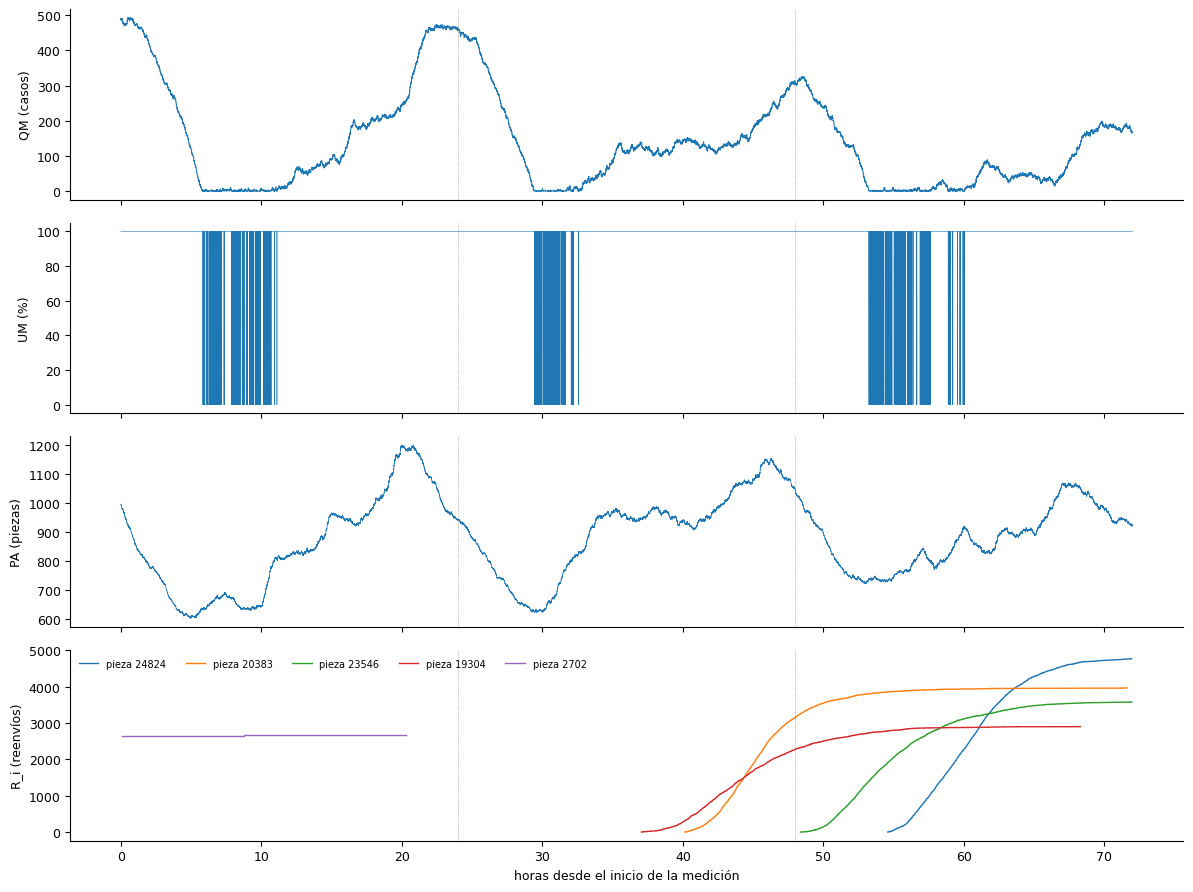

Registros de QM, BM, UM y PA: 67.964; eventos procesados en la réplica: 441.793


In [15]:
sup3 = Supuestos(retardo='mezcla', escala=ESC_B, horizonte_h=72)
inf3, ser3 = sim.correr(Configuracion(), 'conservador', sup3, semilla=5, series=True)
e = ser3['estado']; h = (e.t_min - 24 * 60) / 60
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
ax[0].step(h, e.QM, where='post', lw=.7); ax[0].set_ylabel('QM (casos)')
ax[1].step(h, e.UM, where='post', lw=.4); ax[1].set_ylabel('UM (%)')
ax[2].step(h, e.PA, where='post', lw=.5); ax[2].set_ylabel('PA (piezas)')
Rr = ser3['R']; top = Rr.groupby('pieza').R.max().nlargest(5).index
for pz in top:
    q = Rr[Rr.pieza == pz]; ax[3].step((q.t_min - 24 * 60) / 60, q.R, where='post', lw=1, label=f'pieza {pz}')
ax[3].set_ylabel('R_i (reenvíos)'); ax[3].set_xlabel('horas desde el inicio de la medición'); ax[3].legend(frameon=False, fontsize=7, ncol=5)
for a, d in zip(ax, range(4)):
    for k in range(1, 3): a.axvline(24 * k, color='grey', lw=.5, ls=':')
plt.tight_layout(); plt.show()
print(f'Registros de QM, BM, UM y PA: {n(len(e), 0)}; eventos procesados en la réplica: {n(inf3.eventos_procesados, 0)}')

## 8. Cálculo de la cantidad de réplicas

Las réplicas son terminantes: cada una empieza con la fila vacía y sin piezas activas, descarta el primer día y mide 30 días. Con n₀ réplicas piloto en la situación actual se estima el desvío de cada variable de referencia y la cantidad necesaria para que la semiamplitud del intervalo de confianza del 95 % no supere el 5 % de la media:

n = ⌈(t₀.₉₇₅, n₀−1 · s / (ε · x̄))²⌉, con ε = 0,05.

Se toma el mayor n entre IN, IL y CFP. El cálculo sigue BANKS (p. 429 a 430) y LAW (p. 237 a 238).

In [16]:
CFG0 = Configuracion()          # situación actual: M = 1, C = 0, sin fricción ni degradación
N0 = 10
t0 = time.time()
piloto = en_disco('piloto', lambda: replicar(sim, CFG0, 'conservador', SUP, n=N0, semilla_base=1, procesos=PROCESOS))
print(f'{N0} réplicas piloto en {n(time.time() - t0, 0)} s')
eps = 0.05
filas = []
for v in ['IN', 'IL', 'CFP']:
    x = piloto[v]; t = st.t.ppf(0.975, N0 - 1)
    n_nec = math.ceil((t * x.std(ddof=1) / (eps * x.mean())) ** 2)
    filas.append({'variable': v, 'media piloto': x.mean(), 'desvío piloto': x.std(ddof=1), 'CV': x.std(ddof=1) / x.mean(), 'n necesario': n_nec})
tab_n = pd.DataFrame(filas).set_index('variable')
N = int(max(N0, tab_n['n necesario'].max()))
print(tab_n.to_string())
print(f'\nCantidad de réplicas adoptada: N = {N}')

10 réplicas piloto en 652 s
                media piloto    desvío piloto     CV  n necesario
variable                                                         
IN        7.349.229.006,6986 221.660.864,1486 0,0302            2
IL       11.778.426.347,0954 122.680.977,2732 0,0104            1
CFP               3.895,9500         102,9176 0,0264            2

Cantidad de réplicas adoptada: N = 10


## 9. Corridas en condiciones iniciales con intervalos de confianza

Se completan N réplicas de la situación actual (las piloto más las que faltan, con semillas distintas) y se informan media, desvío e intervalo de confianza del 95 % de cada variable. El criterio de precisión del 5 % se fijó sobre las variables de referencia; las variables de estado de la fila (QM, espera) son mucho más variables entre réplicas y su semiamplitud relativa puede superarlo.

In [17]:
t0 = time.time()
resto = en_disco(f'resto_{N}', lambda: replicar(sim, CFG0, 'conservador', SUP, n=N - N0, semilla_base=N0 + 1, procesos=PROCESOS)) if N > N0 else piloto.iloc[:0]
base_N = pd.concat([piloto, resto], ignore_index=True)
print(f'{len(base_N)} réplicas ({n(time.time() - t0, 0)} s adicionales)')
variables = ['IN', 'IL', 'CFP', 'QM_medio', 'BM_medio', 'UM_medio_pct', 'PA_medio', 'reenvios', 'casos_revisados',
             'remociones_nocivas', 'remociones_legitimas', 'espera_media_fila_min', 'latencia_media_min', 'CF', 'CD']
ic_base = informe_replicas(base_N, variables)
print(ic_base[['media', 'desvio', 'inf', 'sup', 'relativa', 'n']].to_string())

10 réplicas (0 s adicionales)
                                    media           desvio                 inf                 sup  relativa       n
IN                     7.349.229.006,6986 221.660.864,1486  7.190.662.376,7465  7.507.795.636,6507    0,0216 10,0000
IL                    11.778.426.347,0954 122.680.977,2732 11.690.665.662,7718 11.866.187.031,4190    0,0075 10,0000
CFP                            3.895,9500         102,9176          3.822,3272          3.969,5728    0,0189 10,0000
QM_medio                         831,0382         108,3581            753,5235            908,5529    0,0933 10,0000
BM_medio                           0,9894           0,0033              0,9870              0,9917    0,0024 10,0000
UM_medio_pct                      98,9352           0,3330             98,6970             99,1734    0,0024 10,0000
PA_medio                       1.013,9112          10,2804          1.006,5570          1.021,2654    0,0073 10,0000
reenvios                   3.341.1

Latencia desde el marcado (min): observada media 238,2, mediana 140,3; simulada media 364,1 (IC 95 %: 339,0 a 389,2)


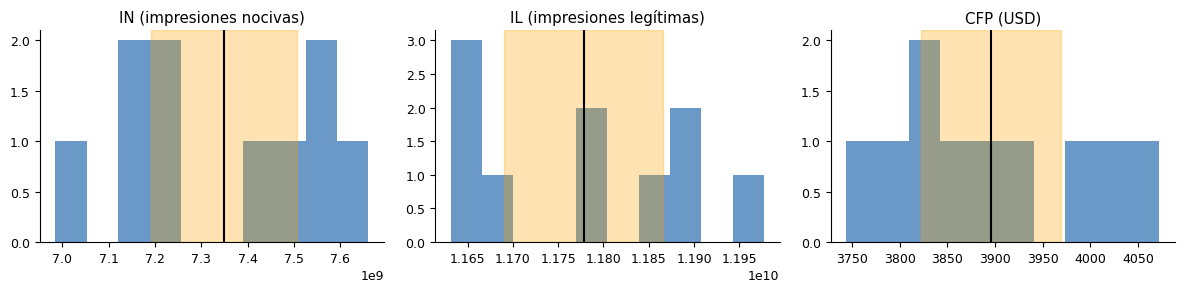

In [18]:
lat_obs = I.observado['latencias']
print(f'Latencia desde el marcado (min): observada media {n(lat_obs.mean(), 1)}, mediana {n(np.median(lat_obs), 1)}; '
      f'simulada media {n(ic_base.loc["latencia_media_min", "media"], 1)} (IC 95 %: {n(ic_base.loc["latencia_media_min", "inf"], 1)} a {n(ic_base.loc["latencia_media_min", "sup"], 1)})')
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, v, t in zip(ax, ['IN', 'IL', 'CFP'], ['IN (impresiones nocivas)', 'IL (impresiones legítimas)', 'CFP (USD)']):
    a.hist(base_N[v], bins=10, color='#2b6cb0', alpha=.7); a.axvline(ic_base.loc[v, 'media'], color='k')
    a.axvspan(ic_base.loc[v, 'inf'], ic_base.loc[v, 'sup'], color='orange', alpha=.3); a.set_title(t)
plt.tight_layout(); plt.show()

**Latencia de la situación actual.** La latencia simulada supera a la observada. La calibración de ESC usa la fórmula de M/M/1, que supone llegadas con tasa constante, mientras que la siembra varía por día y hora: con ρ medio cercano a 1, en las horas de mayor siembra ρ supera 1 y la fila crece. Para medir ese efecto, la celda siguiente repite la situación actual con siembra de tasa constante (misma tasa media, 2 réplicas de 30 días).

In [19]:
def _uniforme():
    s = Supuestos(retardo='mezcla', escala=ESC_B, llegadas_uniformes=True)
    return replicar(sim, CFG0, 'conservador', s, n=2, semilla_base=1, procesos=PROCESOS)
unif = en_disco('latencia_uniforme', _uniforme)
comp_lat = pd.DataFrame({
    'observada (muestra)': [np.nan, lat_obs.mean()],
    'simulada, siembra por día y hora': [base_N.espera_media_fila_min.mean(), base_N.latencia_media_min.mean()],
    'simulada, siembra de tasa constante': [unif.espera_media_fila_min.mean(), unif.latencia_media_min.mean()]},
    index=['espera media en fila (min)', 'latencia media desde el marcado (min)'])
print(comp_lat.to_string())
lo, hi = sorted([unif.latencia_media_min.mean(), base_N.latencia_media_min.mean()])
print('La latencia observada queda ' + ('entre' if lo <= lat_obs.mean() <= hi else 'fuera de') +
      ' las dos latencias simuladas.')

                                       observada (muestra)  simulada, siembra por día y hora  simulada, siembra de tasa constante
espera media en fila (min)                             NaN                          273,7817                              33,6482
latencia media desde el marcado (min)             238,1687                          364,1079                             123,9747
La latencia observada queda entre las dos latencias simuladas.


Con un solo moderador y ρ medio cercano a 1, la latencia depende casi por completo de cómo se reparte la siembra en el tiempo: la misma tasa media da latencias muy distintas según sea constante o varíe por hora. La fila de la situación actual queda, por lo tanto, más cargada que la observada, y las comparaciones que involucren M = 1 deben leerse con esa salvedad. ESC es un supuesto sin datos que la etapa 5 del plan de experimentación vuelve a simular; una alternativa para esa etapa es calibrar ESC directamente por simulación, buscando el valor que reproduce la latencia observada.

## 10. Prueba de estrés

Cada variable de decisión se lleva a su extremo, de a una y todas juntas, y la situación actual se corre también en los escenarios intermedio y pesimista. Para acotar el tiempo de cómputo cada configuración se corre con 3 réplicas de 7 días de medición, con números aleatorios comunes (semillas 1 a 3). Se verifica que el simulador termine sin errores, que las variables de estado se mantengan en sus rangos y que cada palanca mueva las variables de referencia en el sentido esperado.

In [20]:
SUP7 = Supuestos(retardo='mezcla', escala=ESC_B, horizonte_h=7 * 24)
estres = {
    'situación actual': (Configuracion(), 'conservador'),
    'M = 12': (Configuracion(M=12), 'conservador'),
    'C = 2': (Configuracion(C=2), 'conservador'),
    'U = 1, F = 0,9': (Configuracion(U=1, F=0.9), 'conservador'),
    'D = mega y C2, δ = 0,9': (Configuracion(D='mega_c2', delta=0.9), 'conservador'),
    'todas al máximo': (Configuracion(M=12, C=2, U=1, F=0.9, D='mega_c2', delta=0.9), 'conservador'),
    'escenario intermedio': (Configuracion(), 'intermedio'),
    'escenario pesimista': (Configuracion(), 'pesimista'),
}
res_estres = {}
t0 = time.time()
for nombre, (cfg, esc) in estres.items():
    res_estres[nombre] = en_disco('estres_' + str(list(estres).index(nombre)), lambda: replicar(sim, cfg, esc, SUP7, n=3, semilla_base=1, procesos=PROCESOS))
print(f'Prueba de estrés: {n(time.time() - t0, 0)} s')
cols = ['IN', 'IL', 'CFP', 'UM_medio_pct', 'QM_medio', 'PA_medio', 'reenvios_bloqueados', 'remociones_nocivas', 'remociones_legitimas', 'espera_media_fila_min', 'CF', 'segundos']
tab_estres = pd.DataFrame({k: v[cols].mean() for k, v in res_estres.items()}).T
print(tab_estres.to_string(float_format=lambda v: f'{n(v, 2)}'))

Prueba de estrés: 440 s
                                     IN               IL    CFP  UM_medio_pct  QM_medio  PA_medio  reenvios_bloqueados  remociones_nocivas  remociones_legitimas  espera_media_fila_min           CF  segundos
situación actual       1.655.950.718,74 2.790.658.486,66 867,50         96,79    480,42    992,75                 0,00            9.523,33                578,33                 152,50    15.840,00     26,39
M = 12                 1.409.095.607,20 2.772.732.026,10 892,50          8,32      0,00    937,07                 0,00            9.824,67                595,00                   0,00   190.080,00     25,35
C = 2                  1.580.196.449,29 2.795.013.448,33 348,50         93,40    327,93    968,46                 0,00           15.309,67                232,33                 111,28    39.590,00     28,08
U = 1, F = 0,9           485.812.220,27   663.667.452,72 545,50         69,26      9,22    580,68           132.963,67            7.910,33          

In [21]:
b = res_estres['situación actual']
chequeos = []
for k, v in res_estres.items():
    chequeos.append((f'{k}: UM entre 0 y 100, QM y PA no negativos', bool(((v.UM_medio_pct >= 0) & (v.UM_medio_pct <= 100) & (v.QM_medio >= 0) & (v.PA_medio >= 0)).all())))
menor = lambda k, var: bool((res_estres[k][var].values <= b[var].values).all())
mayor = lambda k, var: bool((res_estres[k][var].values >= b[var].values).all())
chequeos += [
    ('M = 12 no aumenta IN en ninguna réplica', menor('M = 12', 'IN')),
    ('C = 2 aumenta las remociones nocivas en cada réplica', mayor('C = 2', 'remociones_nocivas')),
    ('Fricción máxima reduce IN e IL en cada réplica', menor('U = 1, F = 0,9', 'IN') and menor('U = 1, F = 0,9', 'IL')),
    ('Degradación máxima reduce IN e IL en cada réplica', menor('D = mega y C2, δ = 0,9', 'IN') and menor('D = mega y C2, δ = 0,9', 'IL')),
    ('Escenario intermedio aumenta IN e IL en cada réplica', mayor('escenario intermedio', 'IN') and mayor('escenario intermedio', 'IL')),
    ('Escenario pesimista aumenta IN e IL en cada réplica', mayor('escenario pesimista', 'IN') and mayor('escenario pesimista', 'IL')),
]
print(pd.DataFrame(chequeos, columns=['chequeo', 'cumple']).to_string(index=False))

                                                       chequeo  cumple
      situación actual: UM entre 0 y 100, QM y PA no negativos    True
                M = 12: UM entre 0 y 100, QM y PA no negativos    True
                 C = 2: UM entre 0 y 100, QM y PA no negativos    True
        U = 1, F = 0,9: UM entre 0 y 100, QM y PA no negativos    True
D = mega y C2, δ = 0,9: UM entre 0 y 100, QM y PA no negativos    True
       todas al máximo: UM entre 0 y 100, QM y PA no negativos    True
  escenario intermedio: UM entre 0 y 100, QM y PA no negativos    True
   escenario pesimista: UM entre 0 y 100, QM y PA no negativos    True
                       M = 12 no aumenta IN en ninguna réplica    True
          C = 2 aumenta las remociones nocivas en cada réplica    True
                Fricción máxima reduce IN e IL en cada réplica    True
             Degradación máxima reduce IN e IL en cada réplica    True
          Escenario intermedio aumenta IN e IL en cada réplica    True
      

## 11. Diferencias con la parte A

* **Retardo padre-hijo.** La hiperexponencial de dos fases no reproduce la duración de las cascadas (sección 4). El retardo se representa con una mezcla de exponenciales ajustada por máxima verosimilitud a los retardos observados, con dos fases que empiezan después del corte de 55 min. El mecanismo de potencial por generación y fase no cambia: cada fase decae exponencialmente y las fases con espera reciben su potencial al terminar la espera. Para acotar la memoria, el potencial en espera se agrupa en intervalos de un minuto.
* **Escala de siembra.** Se mantiene el criterio de calibración de la parte A (la tasa de casos debe coincidir con λ), pero con la proporción de piezas marcadas que produce el modelo en lugar de la observada (sección 5). ESC es uno de los supuestos sin datos que la etapa 5 del plan de experimentación vuelve a simular. Con la escala recalibrada la fila de la situación actual queda más cargada que la observada (sección 9).
* **Validación.** La parte A comparaba la distribución del tamaño con una banda de 20 réplicas. La validación de la sección 4 usa una prueba de bondad de ajuste por Monte Carlo sobre tamaño, profundidad, duración y proporción de piezas marcadas.
* **Costos de configuración.** Supuestos contables que el plan no fijaba: el capex y el opex del clasificador se cargan solo con C = 1 y C = 2 (con C = 0 se usa el Centinela vigente; si este también tuviera opex, el costo incremental de C = 1 y C = 2 quedaría sobreestimado en el opex mensual); el capex se amortiza en línea recta en la vida útil de Finanzas, sin descuento; la degradación cuesta 120 USD por cuenta mega y día durante 30 días, y solo si D incluye mega (la degradación de piezas C2 no tiene costo informado).
* **Números aleatorios comunes.** Cada pieza tiene su propio generador y sortea al crearse la duración de su revisión y la uniforme de la decisión de remoción; la fricción consume siempre un número por reenvío. Las piezas cuya historia no cambia con la configuración recorren exactamente los mismos números.
* **Indicadores complementarios.** El informe de cada réplica agrega el tamaño y la duración medios de las cascadas sembradas y terminadas dentro de la ventana de medición.

In [22]:
print(f'Tiempo total de ejecución del cuaderno: {n((time.time() - t_inicio_cuaderno) / 60, 1)} min')

Tiempo total de ejecución del cuaderno: 34,0 min
